# Bank Marketing — Logistic Regression Baseline

**Objective:** Predict whether a bank customer subscribes to a term deposit (`y`: `yes`/`no`) using the personalized Bank Marketing dataset.

This notebook preserves the original baseline methodology:
- Logistic Regression with `class_weight="balanced"` and `max_iter=2000`
- Numerical preprocessing: median imputation followed by `StandardScaler`
- Categorical preprocessing: most-frequent imputation followed by `OneHotEncoder`
- Exclude `duration` to model predictions made before the marketing contact takes place
- Stratified 80/20 train-test split using `random_state=202300404`
- Default classification threshold of 0.50 (`Pipeline.predict()`)

No resampling, additional models, feature engineering, hyperparameter tuning, or threshold optimization are performed.

**Execution note:** Place `bank_personalized.csv` in the notebook's working directory, or change `DATASET_PATH` in the first code cell. The notebook checks the expected dataset and split sizes rather than fabricating results.

In [4]:
# 1. Imports and configuration

# Change this path if the dataset is stored elsewhere.
DATASET_PATH = DATASET_PATH = "../data/bank_personalized.csv"

RANDOM_STATE = 202300404
TEST_SIZE = 0.20

EXPECTED_RECORDS = 36168
EXPECTED_TRAIN_RECORDS = 28934
EXPECTED_TEST_RECORDS = 7234

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

print("Imports and configuration loaded.")
print(f"Dataset path: {DATASET_PATH}")
print(f"Random state: {RANDOM_STATE}")

Imports and configuration loaded.
Dataset path: ../data/bank_personalized.csv
Random state: 202300404


## 2. Dataset loading and validation

The personalized dataset is already the required 80% sample of the original data. It is loaded as-is; this notebook does **not** sample it again.

The expected number of records is 36,168. The default `pd.read_csv()` comma-delimited reader is used, as requested. If your file uses a different delimiter, adjust the `read_csv` call to match the actual file format.

In [5]:
# 2. Load the personalized dataset
df = pd.read_csv(DATASET_PATH)

print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())

# Validate the expected record count.
if len(df) != EXPECTED_RECORDS:
    raise ValueError(
        f"Expected {EXPECTED_RECORDS:,} records, but loaded {len(df):,}. "
        "Check DATASET_PATH and confirm that this is the personalized dataset."
    )

if "y" not in df.columns:
    raise ValueError("The dataset must contain the target column 'y'.")

print("Dataset record-count and target-column checks passed.")

Dataset shape: 36,168 rows × 17 columns


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,36,admin.,single,secondary,no,0,yes,no,cellular,14,jul,80,2,-1,0,unknown,no
1,30,admin.,single,tertiary,no,1535,no,no,cellular,18,aug,67,4,-1,0,unknown,no
2,31,unemployed,single,secondary,no,8304,no,no,cellular,20,oct,164,1,183,1,failure,no
3,37,technician,married,secondary,no,54,yes,yes,cellular,22,jul,106,2,-1,0,unknown,no
4,38,blue-collar,single,tertiary,no,14058,no,no,telephone,17,jul,293,20,-1,0,unknown,no


Dataset record-count and target-column checks passed.


## 3. Brief exploratory data analysis

Inspect the feature types, descriptive statistics, missing values, duplicate rows, and target distribution. These checks inform the preprocessing choices and reveal the class balance without using the held-out test set for model fitting.

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 36168 entries, 0 to 36167
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        36168 non-null  int64
 1   job        36168 non-null  str  
 2   marital    36168 non-null  str  
 3   education  36168 non-null  str  
 4   default    36168 non-null  str  
 5   balance    36168 non-null  int64
 6   housing    36168 non-null  str  
 7   loan       36168 non-null  str  
 8   contact    36168 non-null  str  
 9   day        36168 non-null  int64
 10  month      36168 non-null  str  
 11  duration   36168 non-null  int64
 12  campaign   36168 non-null  int64
 13  pdays      36168 non-null  int64
 14  previous   36168 non-null  int64
 15  poutcome   36168 non-null  str  
 16  y          36168 non-null  str  
dtypes: int64(7), str(10)
memory usage: 4.7 MB

Numerical descriptive statistics:


,age,balance,day,duration,campaign,pdays,previous
count,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000
mean,40.945615,1354.703052,15.819564,257.294708,2.769658,40.140704,0.580237
std,10.627015,3017.419829,8.317434,256.711356,3.112769,100.131183,2.385238
min,18.000000,-6847.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,73.000000,8.000000,102.000000,1.000000,-1.000000,0.000000
50%,39.000000,451.000000,16.000000,179.000000,2.000000,-1.000000,0.000000
75%,48.000000,1423.000000,21.000000,318.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



Categorical descriptive statistics:


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,36168,36168,36168,36168,36168,36168,36168,36168,36168,36168
unique,12,3,4,2,2,2,3,12,4,2
top,blue-collar,married,secondary,no,yes,no,cellular,may,unknown,no
freq,7743,21710,18559,35510,20089,30372,23400,11015,29595,31937



Missing values by column:


,missing_values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Exact duplicate rows: 0

Target counts:


,count
y,
no,31937
yes,4231



Target percentages:


,percentage
y,
no,88.3
yes,11.7


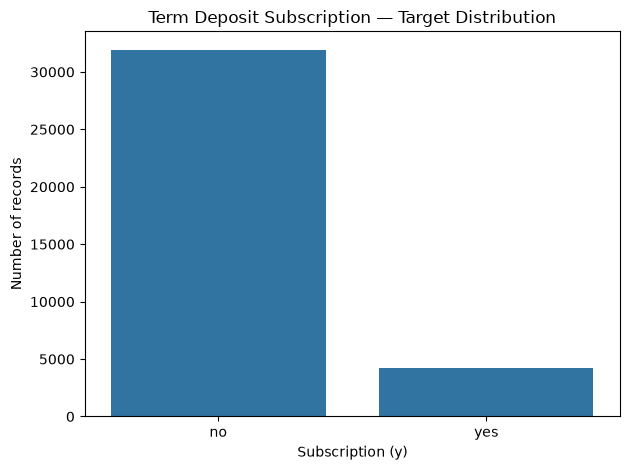

In [6]:
# 3. Explore the dataset
print("Dataset information:")
df.info()

print("\nNumerical descriptive statistics:")
display(df.describe())

print("\nCategorical descriptive statistics:")
display(df.describe(include=["object", "category", "string"]))

print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_values"))

print(f"\nExact duplicate rows: {df.duplicated().sum():,}")

print("\nTarget counts:")
display(df["y"].value_counts(dropna=False).to_frame("count"))

print("\nTarget percentages:")
display(
    (df["y"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
    .to_frame("percentage")
)

ax = sns.countplot(data=df, x="y")
ax.set_title("Term Deposit Subscription — Target Distribution")
ax.set_xlabel("Subscription (y)")
ax.set_ylabel("Number of records")
plt.tight_layout()
plt.show()

## 4. Feature selection and target encoding

The target is encoded as `no = 0` and `yes = 1`. The `duration` feature is deliberately excluded because it is only known after the last contact has taken place; retaining it would not match the intended pre-contact prediction setting.

No other features are removed or engineered.

In [7]:
# 4. Separate predictors and target
target = df["y"].astype("string").str.strip().str.lower()
y = target.map({"no": 0, "yes": 1})

if y.isna().any():
    unexpected = sorted(target[y.isna()].dropna().unique().tolist())
    raise ValueError(
        "Target column 'y' contains missing or unexpected values. "
        f"Unexpected non-missing values: {unexpected}"
    )

y = y.astype("int64")

# Exclude the target and duration from the predictors.
X = df.drop(columns=["y", "duration"], errors="ignore").copy()

if X.shape[1] == 0:
    raise ValueError("No predictor columns remain after excluding 'y' and 'duration'.")

# Identify numerical and categorical columns from their loaded dtypes.
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

unhandled_features = [
    column for column in X.columns
    if column not in numerical_features and column not in categorical_features
]
if unhandled_features:
    raise TypeError(
        "Some columns have unsupported dtypes. Please inspect and convert them: "
        f"{unhandled_features}"
    )

print(f"Predictor count: {X.shape[1]}")
print(f"Numerical features ({len(numerical_features)}): {numerical_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")
print("\nTarget encoding: no = 0, yes = 1")
display(y.value_counts().rename(index={0: "no (0)", 1: "yes (1)"}).to_frame("count"))

Predictor count: 15
Numerical features (6): ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target encoding: no = 0, yes = 1


,count
y,
no (0),31937
yes (1),4231


## 5. Preprocessing pipeline

Numerical columns use **median imputation** and `StandardScaler`. Categorical columns use **most-frequent imputation** and `OneHotEncoder(handle_unknown="ignore")`.

The preprocessing is kept inside the scikit-learn pipeline. Consequently, its imputers, scaler, and encoder are fitted only when the complete pipeline is fitted on the training data. This prevents information from the test set leaking into preprocessing.

In [8]:
# 5. Define preprocessing for each feature type
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
    ],
    remainder="drop",
)

print("Preprocessing pipeline defined.")

Preprocessing pipeline defined.


## 6. Stratified train-test split

Split the personalized dataset once into 80% training and 20% testing data. `stratify=y` preserves the target-class proportions as closely as possible in both partitions.

The expected split sizes are 28,934 training records and 7,234 testing records.

In [9]:
# 6. Split the data; the personalized dataset is not sampled again.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training records: {len(X_train):,}")
print(f"Testing records:  {len(X_test):,}")

if len(X_train) != EXPECTED_TRAIN_RECORDS or len(X_test) != EXPECTED_TEST_RECORDS:
    raise ValueError(
        "Unexpected split sizes. Expected "
        f"{EXPECTED_TRAIN_RECORDS:,} training and {EXPECTED_TEST_RECORDS:,} testing "
        f"records, but received {len(X_train):,} and {len(X_test):,}."
    )

print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: "no", 1: "yes"}).to_frame("proportion"))

print("Testing target proportions:")
display(y_test.value_counts(normalize=True).sort_index().rename(index={0: "no", 1: "yes"}).to_frame("proportion"))

print("Expected dataset and split sizes verified.")

Training records: 28,934
Testing records:  7,234

Training target proportions:


,proportion
y,
no,0.88301
yes,0.11699


Testing target proportions:


,proportion
y,
no,0.883052
yes,0.116948


Expected dataset and split sizes verified.


## 7. Logistic Regression model training

Train the original baseline classifier with `class_weight="balanced"` and `max_iter=2000`. The pipeline ensures preprocessing is fitted on `X_train` only. The test set is not used for training or model selection.

In [10]:
# 7. Build and fit the complete pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

model.fit(X_train, y_train)

print("Logistic Regression pipeline fitted successfully on the training data.")

Logistic Regression pipeline fitted successfully on the training data.


## 8. Predictions and evaluation metrics

Generate class predictions using `Pipeline.predict()`, which uses the classifier's default 0.50 decision threshold. Separately obtain positive-class probabilities for ROC AUC and Average Precision.

All six metrics below are calculated on the held-out test set. No threshold adjustment is performed.

In [11]:
# 8. Predict on the held-out test set
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Calculate the six requested test metrics.
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC AUC": roc_auc_score(y_test, y_prob),
    "Average Precision": average_precision_score(y_test, y_prob),
}

results_df = pd.DataFrame(
    {"Metric": list(metrics.keys()), "Score": list(metrics.values())}
)

print("Held-out test-set performance:")
display(
    results_df.style.format({"Score": "{:.4f}"})
)

print("\nClassification report (default 0.50 threshold):")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No subscription", "Subscription"],
        zero_division=0,
    )
)

Held-out test-set performance:


,Metric,Score
0,Accuracy,0.7567
1,Precision,0.2692
2,Recall,0.6300
3,F1 Score,0.3772
4,ROC AUC,0.7727
5,Average Precision,0.4045



Classification report (default 0.50 threshold):
                 precision    recall  f1-score   support

No subscription       0.94      0.77      0.85      6388
   Subscription       0.27      0.63      0.38       846

       accuracy                           0.76      7234
      macro avg       0.60      0.70      0.61      7234
   weighted avg       0.86      0.76      0.79      7234



## 9. Confusion matrix

The confusion matrix compares actual and predicted classes at the default 0.50 threshold. In this application, a false negative is a potential subscriber who is missed by the model.

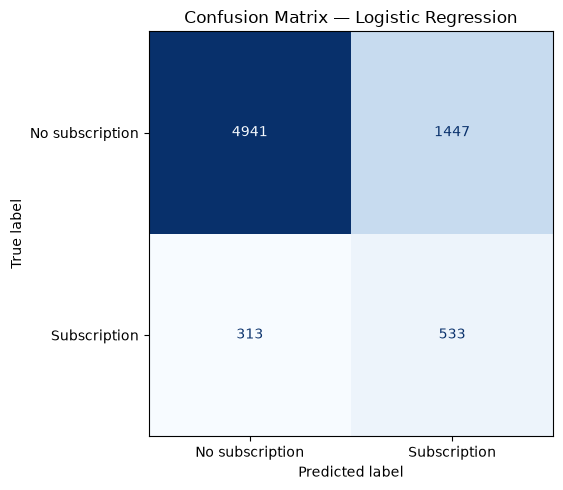

Confusion matrix (rows = actual, columns = predicted):
[[4941 1447]
 [ 313  533]]


In [12]:
# 9. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No subscription", "Subscription"],
)
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)

## 10. ROC and Precision-Recall curves

Both curves use the predicted probabilities for the positive class (`yes`). The ROC curve describes the true-positive/false-positive trade-off across thresholds. The Precision-Recall curve is especially informative when the positive class is less frequent.

The curves are descriptive evaluations on the held-out test set; they are not used to tune the model or select a threshold.

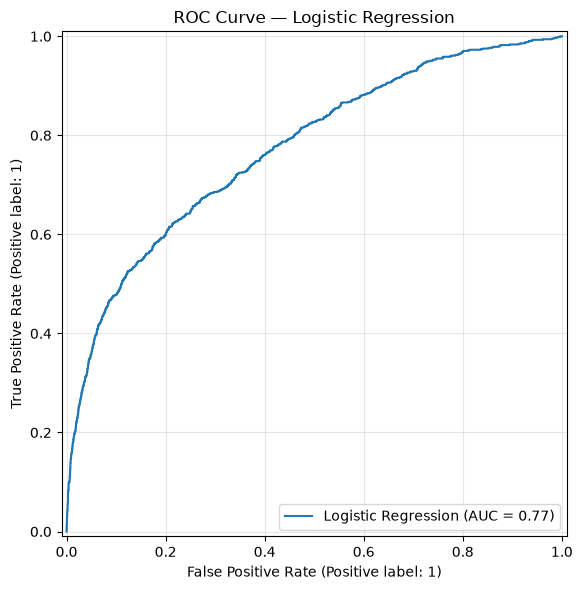

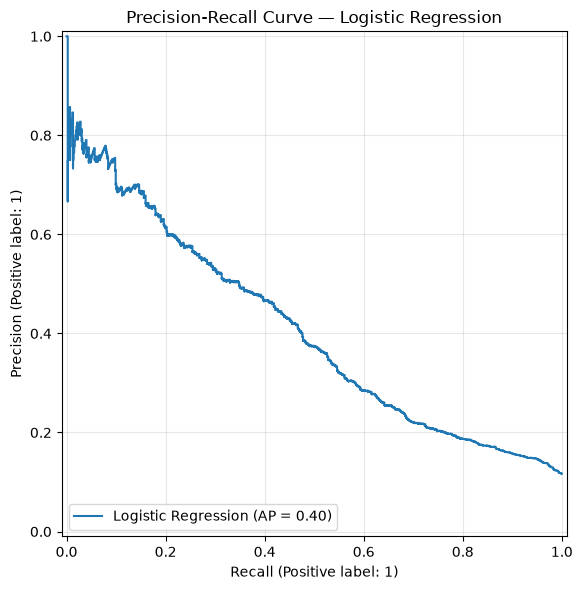

In [13]:
# 10a. ROC curve
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression",
    ax=ax,
)
ax.set_title("ROC Curve — Logistic Regression")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 10b. Precision-Recall curve
fig, ax = plt.subplots(figsize=(7, 6))
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    name="Logistic Regression",
    ax=ax,
)
ax.set_title("Precision-Recall Curve — Logistic Regression")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Final results summary

This section collects the test-set metrics and the dataset/split sizes in one place. The values are calculated when the notebook is run; no performance results are pre-filled or fabricated.

**Methodology corrections for executable, reproducible implementation:** the target is normalized to lowercase strings before encoding, feature types are detected from the loaded DataFrame, and the preprocessing is encapsulated in the same pipeline as the classifier. These are implementation safeguards; they do not change the selected model, imputation strategies, scaling, encoding, excluded feature, split, or classification threshold.

In [14]:
# 11. Final summary
summary = pd.DataFrame(
    {
        "Item": [
            "Dataset records",
            "Training records",
            "Testing records",
            "Predictor features (duration excluded)",
            "Classifier",
            "Class weighting",
            "Maximum iterations",
            "Classification threshold",
        ],
        "Value": [
            len(df),
            len(X_train),
            len(X_test),
            X.shape[1],
            "Logistic Regression",
            "balanced",
            2000,
            0.50,
        ],
    }
)

print("Run summary:")
display(summary)

print("Final held-out test metrics:")
display(results_df.style.format({"Score": "{:.4f}"}))

print(
    "\nNotebook workflow complete. All reported performance values above "
    "were computed from this run's held-out test predictions."
)

Run summary:


,Item,Value
0,Dataset records,36168
1,Training records,28934
2,Testing records,7234
3,Predictor features (duration excluded),15
4,Classifier,Logistic Regression
5,Class weighting,balanced
6,Maximum iterations,2000
7,Classification threshold,0.5


Final held-out test metrics:


,Metric,Score
0,Accuracy,0.7567
1,Precision,0.2692
2,Recall,0.6300
3,F1 Score,0.3772
4,ROC AUC,0.7727
5,Average Precision,0.4045



Notebook workflow complete. All reported performance values above were computed from this run's held-out test predictions.
